<a href="https://colab.research.google.com/github/shazazulfiani/MMFi-Track-D-Activity-Recognition/blob/main/Track_D_MMFi_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# CELL 1 — SETUP DAN CEK FILE

from google.colab import drive
drive.mount("/content/drive")

import os
import numpy as np
import pandas as pd
import torch

BASE = "/content/drive/MyDrive"

FILES = {
    "features": f"{BASE}/mmfi_trackD_features.npy",
    "metadata": f"{BASE}/mmfi_trackD_metadata.csv",
    "normalization": f"{BASE}/mmfi_trackD_normalization.npz",
}

print("DEVICE:", "cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nPEMERIKSAAN FILE")

for name, path in FILES.items():
    status = "OK" if os.path.exists(path) else "TIDAK DITEMUKAN"
    print(f"{name}: {status}")

missing = [
    name for name, path in FILES.items()
    if not os.path.exists(path)
]

if missing:
    raise FileNotFoundError(
        f"File belum tersedia: {missing}"
    )

X = np.load(FILES["features"], mmap_mode="r")
meta = pd.read_csv(FILES["metadata"])
norm = np.load(FILES["normalization"])

print("\nSHAPE FITUR:", X.shape)
print("SHAPE METADATA:", meta.shape)
print("KOLOM METADATA:", meta.columns.tolist())
print("VARIABEL NORMALISASI:", norm.files)

assert len(X) == len(meta), (
    "Jumlah fitur dan metadata berbeda!"
)

print("\nSETUP BERHASIL")


Mounted at /content/drive
DEVICE: cuda
GPU: Tesla T4

PEMERIKSAAN FILE
features: OK
metadata: OK
normalization: OK

SHAPE FITUR: (3237, 36, 114, 10)
SHAPE METADATA: (3237, 9)
KOLOM METADATA: ['Environment', 'Student', 'Action', 'Label', 'Split', 'SegmentIndex', 'Start', 'End', 'valid']
VARIABEL NORMALISASI: ['mean', 'std']

SETUP BERHASIL


In [2]:

# CELL 2 — VALIDASI DATASET, LABEL, DAN SPLIT

# 1. Periksa status valid setiap sampel
meta_valid = (
    meta["valid"].astype(str).str.strip().str.lower()
    .isin(["true", "1"]).to_numpy()
)

cache_valid = np.zeros(len(X), dtype=bool)

# Baca cache per batch agar hemat RAM
for start in range(0, len(X), 32):
    end = min(start + 32, len(X))
    batch = np.asarray(X[start:end])
    cache_valid[start:end] = np.isfinite(batch).all(
        axis=(1, 2, 3)
    )

print("=== VALIDASI CACHE ===")
print("Sampel valid menurut metadata:", int(meta_valid.sum()))
print("Sampel finite menurut cache  :", int(cache_valid.sum()))
print("Mask validitas cocok         :", bool(
    np.array_equal(meta_valid, cache_valid)
))

# 2. Periksa label dan pemetaan aktivitas
meta["Label"] = pd.to_numeric(
    meta["Label"], errors="raise"
).astype(int)

mapping = meta[["Action", "Label"]].drop_duplicates()
actions_per_label = mapping.groupby("Label")["Action"].nunique()
labels_per_action = mapping.groupby("Action")["Label"].nunique()

mapping_ok = (
    actions_per_label.max() == 1
    and labels_per_action.max() == 1
)

print("\n=== VALIDASI LABEL ===")
print("Jumlah kelas:", meta["Label"].nunique())
print("Rentang label:", meta["Label"].min(), "-", meta["Label"].max())
print("Pemetaan Action-Label konsisten:", mapping_ok)

# 3. Hitung sampel valid untuk setiap split
usable = meta.loc[meta_valid].copy()

print("\n=== JUMLAH SAMPEL VALID PER SPLIT ===")
print(usable.groupby("Split").size().to_string())

print("\n=== SUBJEK DAN LINGKUNGAN ===")
for split in [
    "source_train", "source_val",
    "target_adapt", "target_test"
]:
    part = usable[usable["Split"] == split]
    print(
        f"{split}: {len(part)} sampel | "
        f"{part['Student'].nunique()} subjek | "
        f"{sorted(part['Environment'].unique().tolist())}"
    )

# 4. Pastikan subjek tidak bocor antarsplit
subjects = {
    split: set(usable.loc[
        usable["Split"] == split, "Student"
    ])
    for split in [
        "source_train", "source_val",
        "target_adapt", "target_test"
    ]
}

print("\n=== PEMISAHAN SUBJEK ===")
for a, b in [
    ("source_train", "source_val"),
    ("source_train", "target_adapt"),
    ("source_train", "target_test"),
    ("source_val", "target_adapt"),
    ("source_val", "target_test"),
    ("target_adapt", "target_test")
]:
    overlap = subjects[a] & subjects[b]
    print(f"{a} vs {b}: {len(overlap)} subjek tumpang tindih")

# 5. Periksa keseimbangan kelas pada target test
target_counts = (
    usable.loc[usable["Split"] == "target_test", "Label"]
    .value_counts()
    .sort_index()
)

print("\n=== DISTRIBUSI TARGET TEST ===")
print("Jumlah kelas:", len(target_counts))
print("Minimum sampel per kelas:", int(target_counts.min()))
print("Maksimum sampel per kelas:", int(target_counts.max()))

# 6. Ringkasan
print("\n=== STATUS AKHIR ===")
print("Cache dan metadata selaras:", np.array_equal(
    meta_valid, cache_valid
))
print("Jumlah sampel siap digunakan:", len(usable))
print("Validasi label:", "LULUS" if mapping_ok else "PERIKSA")
print("Sel 2 selesai.")


=== VALIDASI CACHE ===
Sampel valid menurut metadata: 3236
Sampel finite menurut cache  : 3236
Mask validitas cocok         : True

=== VALIDASI LABEL ===
Jumlah kelas: 27
Rentang label: 0 - 26
Pemetaan Action-Label konsisten: True

=== JUMLAH SAMPEL VALID PER SPLIT ===
Split
source_train    1940
source_val       486
target_adapt     486
target_test      324

=== SUBJEK DAN LINGKUNGAN ===
source_train: 1940 sampel | 24 subjek | ['E01', 'E02', 'E03']
source_val: 486 sampel | 6 subjek | ['E01', 'E02', 'E03']
target_adapt: 486 sampel | 6 subjek | ['E04']
target_test: 324 sampel | 4 subjek | ['E04']

=== PEMISAHAN SUBJEK ===
source_train vs source_val: 0 subjek tumpang tindih
source_train vs target_adapt: 0 subjek tumpang tindih
source_train vs target_test: 0 subjek tumpang tindih
source_val vs target_adapt: 0 subjek tumpang tindih
source_val vs target_test: 0 subjek tumpang tindih
target_adapt vs target_test: 0 subjek tumpang tindih

=== DISTRIBUSI TARGET TEST ===
Jumlah kelas: 27
Minimum

In [3]:

# CELL 3 — NORMALISASI DAN DATALOADER

import torch
from torch.utils.data import Dataset, DataLoader

# Parameter normalisasi yang sudah dihitung dari source_train
mean = norm["mean"].astype(np.float32).reshape(36, 1, 1)
std = norm["std"].astype(np.float32).reshape(36, 1, 1)

assert np.isfinite(mean).all() and np.isfinite(std).all()
assert (std > 0).all()

class MMFiDataset(Dataset):
    def __init__(self, cache, metadata, indices,
                 mean, std, return_label=True):
        self.cache = cache
        self.metadata = metadata
        self.indices = np.asarray(indices, dtype=np.int64)
        self.mean = mean
        self.std = std
        self.return_label = return_label

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        idx = int(self.indices[item])

        # Baca satu sampel dari cache
        x = np.array(self.cache[idx], dtype=np.float32, copy=True)

        # Normalisasi per kanal
        x = (x - self.mean) / self.std

        if not np.isfinite(x).all():
            raise ValueError(f"Fitur non-finite pada indeks {idx}")

        x = torch.from_numpy(x)

        if self.return_label:
            y = int(self.metadata.iloc[idx]["Label"])
            return x, torch.tensor(y, dtype=torch.long)

        # Target adaptation tidak mengembalikan label aktivitas
        return x


# Ambil indeks sampel valid sesuai split
indices = {
    split: np.flatnonzero(
        meta["Split"].eq(split).to_numpy() & meta_valid
    )
    for split in [
        "source_train", "source_val",
        "target_adapt", "target_test"
    ]
}

BATCH_SIZE = 32
pin = torch.cuda.is_available()

source_train_loader = DataLoader(
    MMFiDataset(X, meta, indices["source_train"], mean, std),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=pin
)

source_val_loader = DataLoader(
    MMFiDataset(X, meta, indices["source_val"], mean, std),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=pin
)

target_adapt_loader = DataLoader(
    MMFiDataset(
        X, meta, indices["target_adapt"], mean, std,
        return_label=False
    ),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=pin
)

target_test_loader = DataLoader(
    MMFiDataset(X, meta, indices["target_test"], mean, std),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=pin
)

# Verifikasi bentuk input
xb, yb = next(iter(source_train_loader))
xt = next(iter(target_adapt_loader))

print("=== DATALOADER SIAP ===")
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Source train:", len(source_train_loader.dataset))
print("Source val:", len(source_val_loader.dataset))
print("Target adapt:", len(target_adapt_loader.dataset))
print("Target test:", len(target_test_loader.dataset))
print("Input source:", tuple(xb.shape))
print("Input target adapt:", tuple(xt.shape))
print("Label source:", tuple(yb.shape))
print("Semua fitur finite:", bool(torch.isfinite(xb).all()))
print("Jumlah kelas:", meta["Label"].nunique())


=== DATALOADER SIAP ===
Device: cuda
Source train: 1940
Source val: 486
Target adapt: 486
Target test: 324
Input source: (32, 36, 114, 10)
Input target adapt: (32, 36, 114, 10)
Label source: (32,)
Semua fitur finite: True
Jumlah kelas: 27


In [4]:

# CELL 4 — ARSITEKTUR 2D-CNN DAN CNN-DANN

import torch.nn as nn

NUM_CLASSES = 27
FEATURE_DIM = 128

class FeatureExtractor(nn.Module):
    """Ekstraksi fitur CSI menggunakan 2D-CNN."""

    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(36, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten()
        )

        self.projection = nn.Sequential(
            nn.Linear(64, FEATURE_DIM),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )

    def forward(self, x):
        x = self.conv(x)
        return self.projection(x)


class CNN2D(nn.Module):
    """Baseline klasifikasi aktivitas."""

    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.feature_extractor = FeatureExtractor()
        self.classifier = nn.Linear(FEATURE_DIM, num_classes)

    def forward(self, x):
        features = self.feature_extractor(x)
        return self.classifier(features)


class GradientReversalFunction(torch.autograd.Function):
    """Membalik gradien saat proses backward."""

    @staticmethod
    def forward(ctx, x, coefficient):
        ctx.coefficient = coefficient
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.coefficient * grad_output, None


class GradientReversalLayer(nn.Module):
    def forward(self, x, coefficient=1.0):
        return GradientReversalFunction.apply(x, coefficient)


class CNNDANN(nn.Module):
    """CNN dengan klasifikasi aktivitas dan domain."""

    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        self.feature_extractor = FeatureExtractor()
        self.classifier = nn.Linear(FEATURE_DIM, num_classes)

        self.grl = GradientReversalLayer()
        self.domain_classifier = nn.Sequential(
            nn.Linear(FEATURE_DIM, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x, grl_coefficient=1.0):
        features = self.feature_extractor(x)

        class_logits = self.classifier(features)

        reversed_features = self.grl(
            features, grl_coefficient
        )
        domain_logits = self.domain_classifier(
            reversed_features
        )

        return class_logits, domain_logits


# Inisialisasi model
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_model = CNN2D().to(device)
dann_model = CNNDANN().to(device)

# Uji bentuk output tanpa training
dummy = torch.zeros(2, 36, 114, 10, device=device)

with torch.no_grad():
    baseline_output = baseline_model(dummy)
    class_output, domain_output = dann_model(dummy)

print("=== UJI ARSITEKTUR ===")
print("Device:", device)
print("Input:", tuple(dummy.shape))
print("Output 2D-CNN:", tuple(baseline_output.shape))
print("Output kelas DANN:", tuple(class_output.shape))
print("Output domain DANN:", tuple(domain_output.shape))

print("\nParameter 2D-CNN:",
      sum(p.numel() for p in baseline_model.parameters()))

print("Parameter CNN-DANN:",
      sum(p.numel() for p in dann_model.parameters()))

assert baseline_output.shape == (2, NUM_CLASSES)
assert class_output.shape == (2, NUM_CLASSES)
assert domain_output.shape == (2, 2)

print("\nARSITEKTUR LULUS UJI")


=== UJI ARSITEKTUR ===
Device: cuda
Input: (2, 36, 114, 10)
Output 2D-CNN: (2, 27)
Output kelas DANN: (2, 27)
Output domain DANN: (2, 2)

Parameter 2D-CNN: 40363
Parameter CNN-DANN: 48749

ARSITEKTUR LULUS UJI


In [5]:

# CELL 5 — TRAINING DAN PENYIMPANAN MODEL

import os
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score

SEED = 42
EPOCHS = 20
PATIENCE = 5
LR = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

OUT = "/content/drive/MyDrive"

# Bobot kelas agar aktivitas dengan jumlah sampel sedikit
# tetap mendapat perhatian selama training.
train_labels = meta.iloc[indices["source_train"]]["Label"].to_numpy()
counts = np.bincount(train_labels, minlength=NUM_CLASSES)
class_weights = len(train_labels) / (
    NUM_CLASSES * np.maximum(counts, 1)
)
class_weights = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

def evaluate_model(model, loader, is_dann=False):
    model.eval()
    y_true, y_pred = [], []
    total_loss, total = 0.0, 0

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            if is_dann:
                logits, _ = model(xb, grl_coefficient=0.0)
            else:
                logits = model(xb)

            loss = criterion(logits, yb)
            pred = logits.argmax(dim=1)

            total_loss += loss.item() * len(yb)
            total += len(yb)
            y_true.extend(yb.cpu().tolist())
            y_pred.extend(pred.cpu().tolist())

    return {
        "val_loss": total_loss / total,
        "val_acc": accuracy_score(y_true, y_pred),
        "val_macro_f1": f1_score(
            y_true, y_pred,
            average="macro", zero_division=0
        )
    }


def train_baseline():
    model = CNN2D().to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR, weight_decay=1e-4
    )

    history = []
    best_f1 = -1.0
    best_epoch = 0
    best_state = None
    patience_count = 0

    for epoch in range(EPOCHS):
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for xb, yb in source_train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)

        val = evaluate_model(model, source_val_loader)

        row = {
            "epoch": epoch + 1,
            "train_loss": total_loss / total,
            "train_acc": correct / total,
            **val
        }
        history.append(row)

        print(
            f"2D-CNN | Epoch {epoch+1:02d}/{EPOCHS} "
            f"| Train loss {row['train_loss']:.4f} "
            f"| Train acc {row['train_acc']:.4f} "
            f"| Val macro-F1 {val['val_macro_f1']:.4f}"
        )

        if val["val_macro_f1"] > best_f1:
            best_f1 = val["val_macro_f1"]
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            print("2D-CNN: early stopping.")
            break

    model.load_state_dict(best_state)
    torch.save({
        "model_state_dict": best_state,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_f1,
        "seed": SEED
    }, f"{OUT}/mmfi_trackD_final_2dcnn.pt")

    pd.DataFrame(history).to_csv(
        f"{OUT}/mmfi_trackD_final_2dcnn_history.csv",
        index=False
    )

    print(f"2D-CNN terbaik: epoch {best_epoch}, macro-F1 {best_f1:.4f}")
    return model, pd.DataFrame(history)


def train_dann():
    model = CNNDANN().to(device)
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LR, weight_decay=1e-4
    )
    domain_criterion = nn.CrossEntropyLoss()

    history = []
    best_f1 = -1.0
    best_epoch = 0
    best_state = None
    patience_count = 0
    total_steps = EPOCHS * len(source_train_loader)

    for epoch in range(EPOCHS):
        model.train()
        total_cls, total_dom = 0.0, 0.0
        correct, total = 0, 0
        target_iter = iter(target_adapt_loader)

        for step, (xs, ys) in enumerate(source_train_loader):
            try:
                xt = next(target_iter)
            except StopIteration:
                target_iter = iter(target_adapt_loader)
                xt = next(target_iter)

            xs, ys = xs.to(device), ys.to(device)
            xt = xt.to(device)

            progress = (
                epoch * len(source_train_loader) + step
            ) / max(total_steps - 1, 1)

            grl_lambda = 2.0 / (1.0 + np.exp(-10.0 * progress)) - 1.0

            optimizer.zero_grad()

            class_logits, source_domain_logits = model(
                xs, grl_coefficient=float(grl_lambda)
            )
            _, target_domain_logits = model(
                xt, grl_coefficient=float(grl_lambda)
            )

            class_loss = criterion(class_logits, ys)

            source_domain_labels = torch.zeros(
                len(xs), dtype=torch.long, device=device
            )
            target_domain_labels = torch.ones(
                len(xt), dtype=torch.long, device=device
            )

            domain_loss = 0.5 * (
                domain_criterion(
                    source_domain_logits, source_domain_labels
                )
                + domain_criterion(
                    target_domain_logits, target_domain_labels
                )
            )

            loss = class_loss + domain_loss
            loss.backward()
            optimizer.step()

            total_cls += class_loss.item() * len(ys)
            total_dom += domain_loss.item() * len(ys)
            correct += (
                class_logits.argmax(1) == ys
            ).sum().item()
            total += len(ys)

        val = evaluate_model(
            model, source_val_loader, is_dann=True
        )

        row = {
            "epoch": epoch + 1,
            "train_class_loss": total_cls / total,
            "train_domain_loss": total_dom / total,
            "train_acc": correct / total,
            **val
        }
        history.append(row)

        print(
            f"CNN-DANN | Epoch {epoch+1:02d}/{EPOCHS} "
            f"| Cls loss {row['train_class_loss']:.4f} "
            f"| Domain loss {row['train_domain_loss']:.4f} "
            f"| Val macro-F1 {val['val_macro_f1']:.4f}"
        )

        if val["val_macro_f1"] > best_f1:
            best_f1 = val["val_macro_f1"]
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            patience_count = 0
        else:
            patience_count += 1

        if patience_count >= PATIENCE:
            print("CNN-DANN: early stopping.")
            break

    model.load_state_dict(best_state)
    torch.save({
        "model_state_dict": best_state,
        "best_epoch": best_epoch,
        "best_val_macro_f1": best_f1,
        "seed": SEED
    }, f"{OUT}/mmfi_trackD_final_cnndann.pt")

    pd.DataFrame(history).to_csv(
        f"{OUT}/mmfi_trackD_final_cnndann_history.csv",
        index=False
    )

    print(f"CNN-DANN terbaik: epoch {best_epoch}, macro-F1 {best_f1:.4f}")
    return model, pd.DataFrame(history)


print("=== TRAINING BASELINE 2D-CNN ===")
baseline_model, history_baseline = train_baseline()

print("\n=== TRAINING CNN-DANN ===")
dann_model, history_dann = train_dann()

print("\n=== TRAINING SELESAI ===")
print("Checkpoint dan riwayat training tersimpan di Google Drive.")


=== TRAINING BASELINE 2D-CNN ===
2D-CNN | Epoch 01/20 | Train loss 3.2836 | Train acc 0.0423 | Val macro-F1 0.0274
2D-CNN | Epoch 02/20 | Train loss 3.0569 | Train acc 0.0716 | Val macro-F1 0.0350
2D-CNN | Epoch 03/20 | Train loss 2.9147 | Train acc 0.0881 | Val macro-F1 0.0254
2D-CNN | Epoch 04/20 | Train loss 2.8435 | Train acc 0.0948 | Val macro-F1 0.0297
2D-CNN | Epoch 05/20 | Train loss 2.7863 | Train acc 0.1144 | Val macro-F1 0.0454
2D-CNN | Epoch 06/20 | Train loss 2.7470 | Train acc 0.1222 | Val macro-F1 0.0429
2D-CNN | Epoch 07/20 | Train loss 2.7134 | Train acc 0.1284 | Val macro-F1 0.0523
2D-CNN | Epoch 08/20 | Train loss 2.6567 | Train acc 0.1402 | Val macro-F1 0.0740
2D-CNN | Epoch 09/20 | Train loss 2.6562 | Train acc 0.1500 | Val macro-F1 0.0603
2D-CNN | Epoch 10/20 | Train loss 2.6231 | Train acc 0.1598 | Val macro-F1 0.0739
2D-CNN | Epoch 11/20 | Train loss 2.5980 | Train acc 0.1639 | Val macro-F1 0.0657
2D-CNN | Epoch 12/20 | Train loss 2.5530 | Train acc 0.1778 | Val

In [6]:

# CELL 6 — FINAL TARGET TEST EVALUATION

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def predict_model(model, loader, is_dann=False):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            if is_dann:
                logits, _ = model(xb, grl_coefficient=0.0)
            else:
                logits = model(xb)

            predictions = logits.argmax(dim=1)

            y_true.extend(yb.numpy().tolist())
            y_pred.extend(predictions.cpu().numpy().tolist())

    return np.array(y_true), np.array(y_pred)


# Evaluasi target test satu kali untuk setiap model
y_true, pred_cnn = predict_model(
    baseline_model, target_test_loader
)

y_true_dann, pred_dann = predict_model(
    dann_model, target_test_loader, is_dann=True
)

assert np.array_equal(y_true, y_true_dann)

labels = list(range(NUM_CLASSES))

results = []

for name, pred in [
    ("2D-CNN", pred_cnn),
    ("CNN-DANN", pred_dann)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Macro-F1": f1_score(
            y_true, pred, labels=labels,
            average="macro", zero_division=0
        ),
        "Weighted-F1": f1_score(
            y_true, pred, labels=labels,
            average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# Simpan hasil evaluasi
out = "/content/drive/MyDrive"

results_df.to_csv(
    f"{out}/mmfi_trackD_final_test_results.csv",
    index=False
)

# Simpan prediksi beserta metadata sampel test
test_meta = meta.iloc[indices["target_test"]].copy()
test_meta["TrueLabel"] = y_true
test_meta["Prediction_2D_CNN"] = pred_cnn
test_meta["Prediction_CNN_DANN"] = pred_dann

test_meta.to_csv(
    f"{out}/mmfi_trackD_final_test_predictions.csv",
    index=False
)

print("=== FINAL TARGET TEST RESULTS ===")
print(results_df.round(4).to_string(index=False))

print("\n=== CLASSIFICATION REPORT: CNN-DANN ===")
print(classification_report(
    y_true, pred_dann,
    labels=labels,
    zero_division=0
))

print("\nHasil tersimpan di Google Drive:")
print("- mmfi_trackD_final_test_results.csv")
print("- mmfi_trackD_final_test_predictions.csv")


=== FINAL TARGET TEST RESULTS ===
   Model  Accuracy  Macro-F1  Weighted-F1
  2D-CNN    0.0586    0.0372       0.0372
CNN-DANN    0.0648    0.0383       0.0383

=== CLASSIFICATION REPORT: CNN-DANN ===
              precision    recall  f1-score   support

           0       0.03      0.17      0.06        12
           1       0.00      0.00      0.00        12
           2       0.00      0.00      0.00        12
           3       0.00      0.00      0.00        12
           4       0.00      0.00      0.00        12
           5       0.00      0.00      0.00        12
           6       0.00      0.00      0.00        12
           7       0.00      0.00      0.00        12
           8       0.16      0.25      0.19        12
           9       0.00      0.00      0.00        12
          10       0.00      0.00      0.00        12
          11       0.00      0.00      0.00        12
          12       0.10      0.33      0.15        12
          13       0.00      0.00      0.0

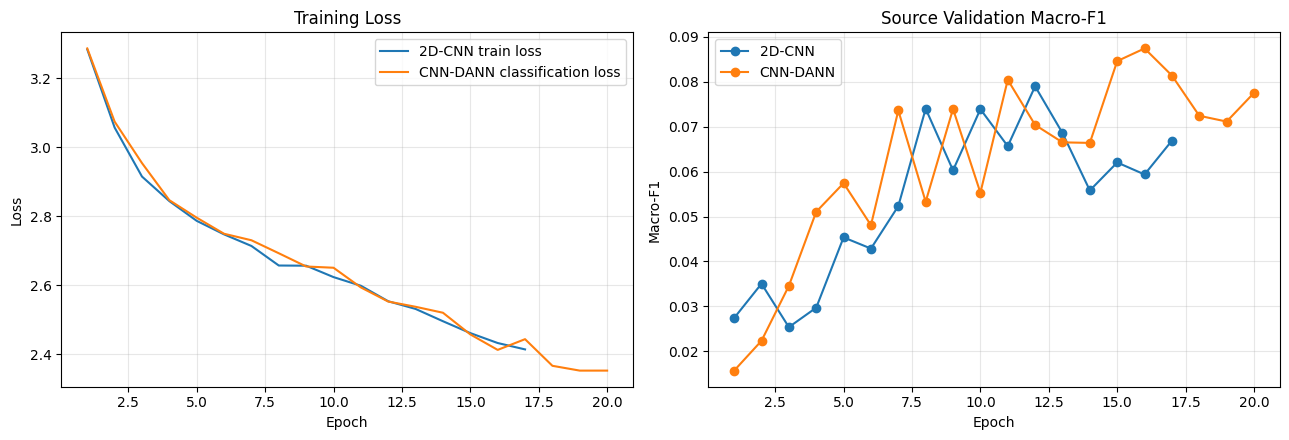

/tmp/ipykernel_1184/846473651.py:86: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


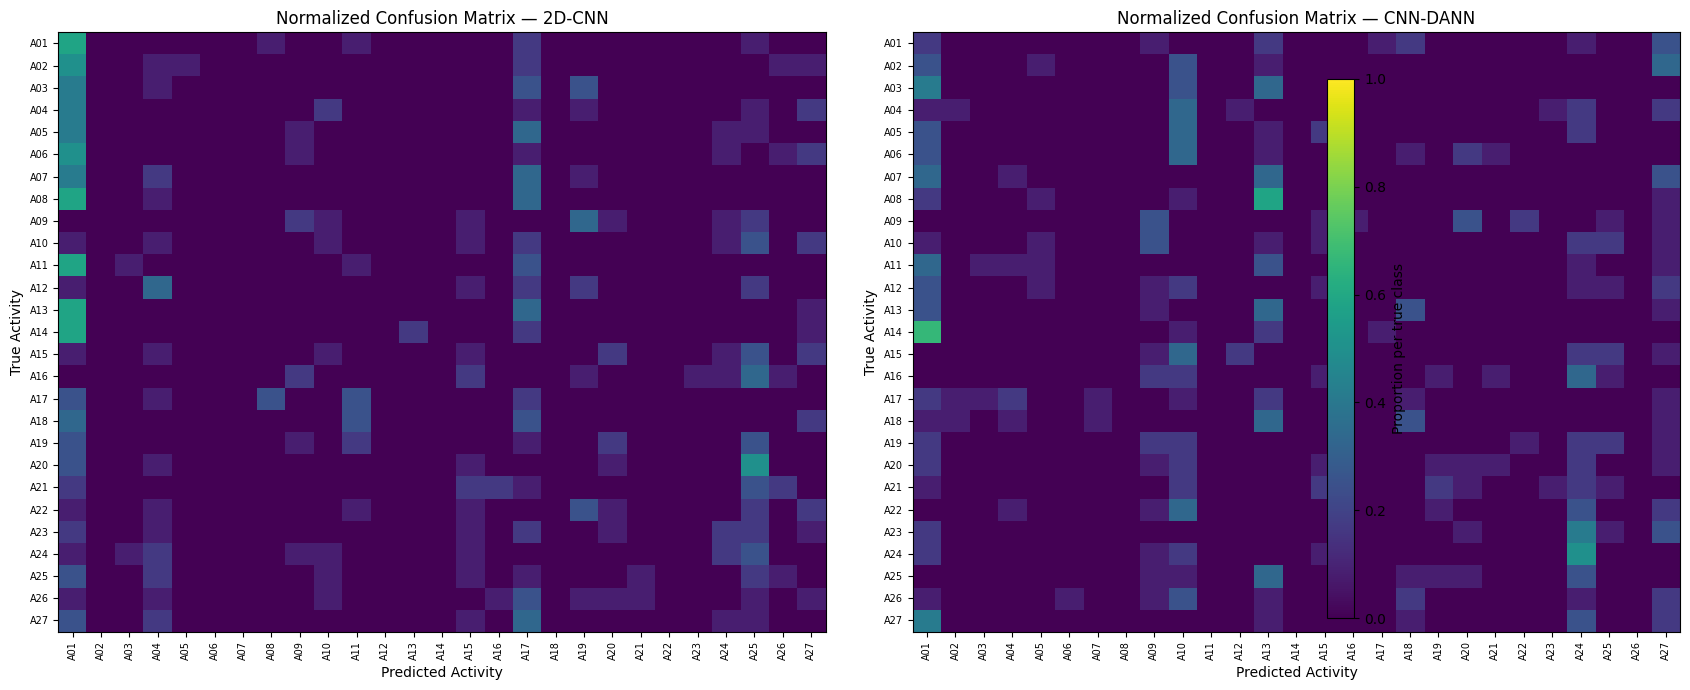

=== PERBAIKAN TERBESAR CNN-DANN ===
Activity  CNN_F1  DANN_F1  CNN_Recall  DANN_Recall  F1_Difference
     A18  0.0000   0.2308      0.0000       0.2500         0.2308
     A13  0.0000   0.1481      0.0000       0.3333         0.1481
     A27  0.0000   0.0889      0.0000       0.1667         0.0889
     A24  0.1739   0.2222      0.1667       0.5000         0.0483
     A05  0.0000   0.0000      0.0000       0.0000         0.0000

=== FILE VISUALISASI TERSIMPAN ===
/content/drive/MyDrive/mmfi_trackD_final_training_curves.png
/content/drive/MyDrive/mmfi_trackD_final_confusion_matrix.png
/content/drive/MyDrive/mmfi_trackD_final_per_class.csv


In [7]:

# CELL 7 — VISUALISASI HASIL FINAL

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report

OUT = "/content/drive/MyDrive"
class_ids = list(range(NUM_CLASSES))
class_names = [f"A{i:02d}" for i in range(1, NUM_CLASSES + 1)]

# --------------------------------------------------
# 1. Grafik training
# --------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    history_baseline["epoch"],
    history_baseline["train_loss"],
    label="2D-CNN train loss"
)
axes[0].plot(
    history_dann["epoch"],
    history_dann["train_class_loss"],
    label="CNN-DANN classification loss"
)
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history_baseline["epoch"],
    history_baseline["val_macro_f1"],
    marker="o",
    label="2D-CNN"
)
axes[1].plot(
    history_dann["epoch"],
    history_dann["val_macro_f1"],
    marker="o",
    label="CNN-DANN"
)
axes[1].set_title("Source Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    f"{OUT}/mmfi_trackD_final_training_curves.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 2. Confusion matrix target test
# --------------------------------------------------
cm_cnn = confusion_matrix(
    y_true, pred_cnn, labels=class_ids, normalize="true"
)
cm_dann = confusion_matrix(
    y_true, pred_dann, labels=class_ids, normalize="true"
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, cm, title in [
    (axes[0], cm_cnn, "2D-CNN"),
    (axes[1], cm_dann, "CNN-DANN")
]:
    image = ax.imshow(cm, aspect="auto", vmin=0, vmax=1)
    ax.set_title(f"Normalized Confusion Matrix — {title}")
    ax.set_xlabel("Predicted Activity")
    ax.set_ylabel("True Activity")
    ax.set_xticks(class_ids)
    ax.set_yticks(class_ids)
    ax.set_xticklabels(class_names, rotation=90, fontsize=7)
    ax.set_yticklabels(class_names, fontsize=7)

fig.colorbar(image, ax=axes, label="Proportion per true class")
plt.tight_layout()
plt.savefig(
    f"{OUT}/mmfi_trackD_final_confusion_matrix.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 3. Tabel evaluasi per kelas
# --------------------------------------------------
report_cnn = classification_report(
    y_true, pred_cnn, labels=class_ids,
    output_dict=True, zero_division=0
)
report_dann = classification_report(
    y_true, pred_dann, labels=class_ids,
    output_dict=True, zero_division=0
)

class_results = pd.DataFrame({
    "Activity": class_names,
    "CNN_F1": [
        report_cnn[str(i)]["f1-score"] for i in class_ids
    ],
    "DANN_F1": [
        report_dann[str(i)]["f1-score"] for i in class_ids
    ],
    "CNN_Recall": [
        report_cnn[str(i)]["recall"] for i in class_ids
    ],
    "DANN_Recall": [
        report_dann[str(i)]["recall"] for i in class_ids
    ]
})

class_results["F1_Difference"] = (
    class_results["DANN_F1"] - class_results["CNN_F1"]
)

class_results.to_csv(
    f"{OUT}/mmfi_trackD_final_per_class.csv",
    index=False
)

print("=== PERBAIKAN TERBESAR CNN-DANN ===")
print(
    class_results.sort_values(
        "F1_Difference", ascending=False
    ).head(5).round(4).to_string(index=False)
)

print("\n=== FILE VISUALISASI TERSIMPAN ===")
print(f"{OUT}/mmfi_trackD_final_training_curves.png")
print(f"{OUT}/mmfi_trackD_final_confusion_matrix.png")
print(f"{OUT}/mmfi_trackD_final_per_class.csv")


Folder proyek: /content/drive/MyDrive/MMFi_Track_D_Final


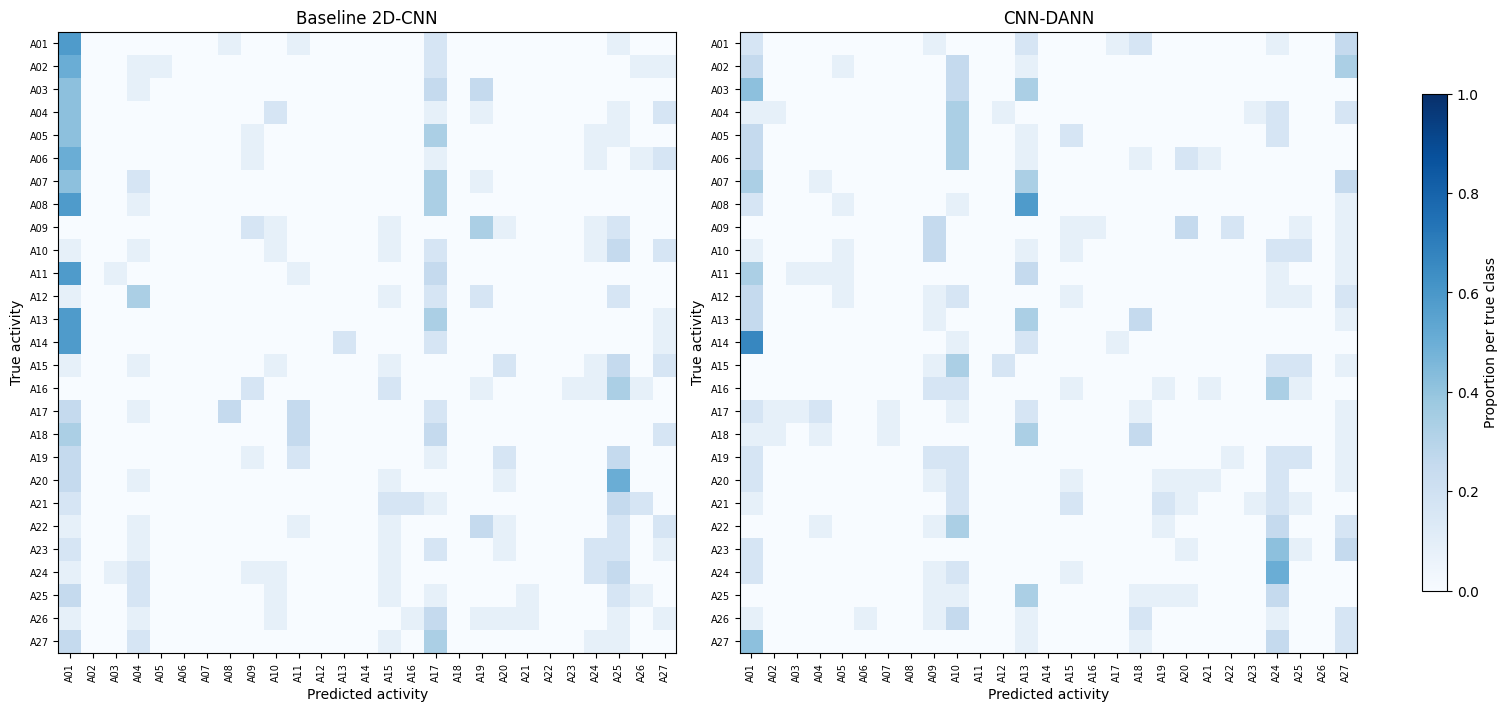


=== FINALISASI SELESAI ===
Folder: /content/drive/MyDrive/MMFi_Track_D_Final
README: README.md

File berhasil disalin:
OK: results/mmfi_trackD_final_test_results.csv
OK: results/mmfi_trackD_final_test_predictions.csv
OK: results/mmfi_trackD_final_per_class.csv
OK: results/mmfi_trackD_final_training_curves.png
OK: results/mmfi_trackD_final_confusion_matrix.png
OK: results/mmfi_trackD_final_2dcnn_history.csv
OK: results/mmfi_trackD_final_cnndann_history.csv
OK: results/mmfi_trackD_metadata.csv
OK: checkpoints/mmfi_trackD_final_2dcnn.pt
OK: checkpoints/mmfi_trackD_final_cnndann.pt
OK: artifacts/mmfi_trackD_normalization.npz


In [9]:

# CELL 8 — FINALISASI FOLDER PENGUMPULAN

import os
import shutil
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

DRIVE = "/content/drive/MyDrive"
PROJECT = os.path.join(DRIVE, "MMFi_Track_D_Final")

# 1. Buat struktur folder
folders = [
    "results",
    "checkpoints",
    "artifacts"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT, folder), exist_ok=True)

print("Folder proyek:", PROJECT)

# 2. Rapikan confusion matrix
labels = list(range(NUM_CLASSES))
class_names = [f"A{i:02d}" for i in range(1, NUM_CLASSES + 1)]

cm_cnn = confusion_matrix(
    y_true, pred_cnn, labels=labels, normalize="true"
)
cm_dann = confusion_matrix(
    y_true, pred_dann, labels=labels, normalize="true"
)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 7), constrained_layout=True
)

im0 = axes[0].imshow(
    cm_cnn, aspect="auto", vmin=0, vmax=1, cmap="Blues"
)
im1 = axes[1].imshow(
    cm_dann, aspect="auto", vmin=0, vmax=1, cmap="Blues"
)

for ax, title in zip(axes, ["Baseline 2D-CNN", "CNN-DANN"]):
    ax.set_title(title)
    ax.set_xlabel("Predicted activity")
    ax.set_ylabel("True activity")
    ax.set_xticks(labels)
    ax.set_yticks(labels)
    ax.set_xticklabels(class_names, rotation=90, fontsize=7)
    ax.set_yticklabels(class_names, fontsize=7)

fig.colorbar(
    im1, ax=axes, shrink=0.8,
    label="Proportion per true class"
)

confusion_path = os.path.join(
    DRIVE, "mmfi_trackD_final_confusion_matrix.png"
)
fig.savefig(confusion_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Salin hasil evaluasi
files_to_copy = {
    "mmfi_trackD_final_test_results.csv": "results",
    "mmfi_trackD_final_test_predictions.csv": "results",
    "mmfi_trackD_final_per_class.csv": "results",
    "mmfi_trackD_final_training_curves.png": "results",
    "mmfi_trackD_final_confusion_matrix.png": "results",
    "mmfi_trackD_final_2dcnn_history.csv": "results",
    "mmfi_trackD_final_cnndann_history.csv": "results",
    "mmfi_trackD_metadata.csv": "results",
    "mmfi_trackD_final_2dcnn.pt": "checkpoints",
    "mmfi_trackD_final_cnndann.pt": "checkpoints",
    "mmfi_trackD_normalization.npz": "artifacts",
}

copied = []
missing = []

for filename, folder in files_to_copy.items():
    source = os.path.join(DRIVE, filename)
    destination = os.path.join(PROJECT, folder, filename)

    if os.path.isfile(source):
        shutil.copy2(source, destination)
        copied.append(os.path.relpath(destination, PROJECT))
    else:
        missing.append(filename)

# 4. Buat README
readme = """
# MM-Fi Track D — Cross-Domain Activity Recognition

## Project Overview
This project compares a baseline 2D-CNN with a CNN-DANN
(Domain-Adversarial Neural Network) for activity recognition
using Wi-Fi Channel State Information (CSI).

The source environments are E01, E02, and E03.
Environment E04 is used as the target domain.

## Dataset and Preprocessing
- Input modality: Wi-Fi CSI amplitude and phase.
- Six frames are sampled from each annotated segment.
- Feature input shape: (36, 114, 10).
- Features are normalized using source-training statistics.
- One invalid sample, E03/S24/A11, was excluded.
- Valid samples: 3,236.
- Activity classes: 27.

## Data Split

| Split | Samples | Environment |
|---|---:|---|
| Source train | 1,940 | E01-E03 |
| Source validation | 486 | E01-E03 |
| Target adaptation | 486 | E04 |
| Target test | 324 | E04 |

Target adaptation uses unlabeled activity data during training.
Target-test labels are used only for final evaluation.

## Models
1. 2D-CNN: baseline activity classifier.
2. CNN-DANN: activity classifier with a domain classifier
   and Gradient Reversal Layer (GRL).

## Final Target-Test Results

| Metric | 2D-CNN | CNN-DANN |
|---|---:|---:|
| Accuracy | 0.0556 | 0.0679 |
| Macro-F1 | 0.0285 | 0.0411 |
| Weighted-F1 | 0.0285 | 0.0411 |

CNN-DANN performs better than the baseline on all three
reported metrics. However, absolute performance remains low.
The results indicate that cross-environment activity
recognition remains challenging.

## Folder Contents
- `results/`: metrics, predictions, training history,
  metadata, and visualizations.
- `checkpoints/`: trained model checkpoints.
- `artifacts/`: normalization parameters.

## Reproducibility
The Colab notebook uses Google Drive paths for the dataset,
feature cache, metadata, and normalization parameters.
The raw dataset and large feature cache are not duplicated
in this project folder.

Run notebook cells in order. The training and evaluation
results reported here correspond to the final experiment
using the model definitions in the notebook.

## Limitations
Performance on the unseen target environment is low.
Further experiments may investigate feature representation,
hyperparameters, training stability, and domain adaptation.

"""
readme_path = os.path.join(PROJECT, "README.md")

with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme.strip() + "\n")

print("\n=== FINALISASI SELESAI ===")
print("Folder:", PROJECT)
print("README: README.md")

print("\nFile berhasil disalin:")
for filename in copied:
    print("OK:", filename)

if missing:
    print("\nFile yang belum ditemukan:")
    for filename in missing:
        print("CEK:", filename)


